<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/%D0%9F%D1%80%D0%BE%D1%94%D0%BA%D1%82_%D0%B2%D1%96%D0%B4_Kaggle_%D0%B4%D0%B0%D1%82%D0%B0%D1%81%D0%B5%D1%82%D1%83_%D0%B4%D0%BE_%D0%BF%D0%B5%D1%80%D1%88%D0%BE%D1%97_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%96.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ппроєкт: від Kaggle-датасету до першої моделі

## 1. Проєкт: що і як

**Завдання:** побудувати прогнозну модель на реальному датасеті з Kaggle: очистити дані, створити
ознаки, порівняти моделі з коректною валідацією, пояснити модель і написати висновок для бізнесу.

**Датасети на вибір** (усі публічні, завантажуються через `kagglehub` без реєстрації):

| № | Датасет | Задача | Чим цікавий |
|---|---|---|---|
| 1 | [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) | класифікація: чи піде клієнт | числа, записані як текст; бізнес-розрахунок утримання |
| 2 | [Hotel Booking Demand](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand) | класифікація: чи скасують бронювання | **витоки цілі**, дублікати, валідація за часом, 119 тис. рядків |
| 3 | [New York City Airbnb](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data) | регресія: ціна за ніч | викиди, пропуски, багато категорій, логарифм цілі |

Складність зростає від 1 до 3

---
## Практика: старт власного проєкту

1. Відкрийте `project_template.ipynb`, збережіть копію у свій Google Drive
   (`Файл → Зберегти копію на Диску`).
2. Оберіть датасет і змініть `DATASET` і `FILE` у комірці завантаження.
3. Заповніть **розділ 1** (постановка). Покажіть викладачу до кінця заняття.
4. Почніть **розділ 2** (аудит): типи колонок, пропуски, дублікати, ціль, витоки.

**Підказки до датасетів (без спойлерів):**
- **Telco:** перевірте тип кожної «числової» колонки — чи справді вона число?
- **Hotel:** для кожної колонки запитайте: «Чи відомо це в момент бронювання?» Подумайте, як
  розділити дані, щоб модель прогнозувала майбутні бронювання.
- **Airbnb:** подивіться на мінімальні й максимальні ціни. Чи всі оголошення реальні?

## 2. Демонстрація: проєкт у мініатюрі

Пройдемо всі розділи шаблону швидко на датасеті [IBM HR Analytics Employee Attrition](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset)
(його немає серед варіантів проєкту). Мета — побачити **порядок дій**, а не ідеальний результат.

### 0. Завантаження з Kaggle

| Columns | Values |
| ------- | ------ |
| Age | Вік працівника |


In [1]:
import os
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import kagglehub
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
    import kagglehub

path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")
print(os.listdir(path))
ibm = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-HR-Employee-Attrition.csv"))
print(ibm.shape)
ibm.head(3)

Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
['WA_Fn-UseC_-HR-Employee-Attrition.csv']
(1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0


### 1. Постановка

- **Замовник:** HR; рішення — кому запропонувати програму утримання.
- **Ціль:** `Attrition` (Yes/No) → класифікація; один рядок — працівник.
- **Метрика:** ROC-AUC (ранжування за ризиком) + recall у топ-15 % списку; бізнес — вартість заміни.

### 2. Аудит

In [2]:
ibm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [3]:
ibm['Attrition'].value_counts()

,count
Attrition,
No,1233
Yes,237


In [4]:
print("Дублікати:", ibm.duplicated().sum())
print("Пропуски:", ibm.isna().sum().sum())
print("Частка звільнень:", (ibm['Attrition'] == 'Yes').mean().round(3))

Дублікати: 0
Пропуски: 0
Частка звільнень: 0.161


In [5]:
print('Ідентифікатор: EmployeeNumber', ibm['EmployeeNumber'].is_unique)

Ідентифікатор: EmployeeNumber True


In [6]:
constant = [c for c in ibm.columns if ibm[c].nunique() == 1]
print('Константи:', constant)

Константи: ['EmployeeCount', 'Over18', 'StandardHours']


In [7]:
df = ibm.drop(columns=constant + ['EmployeeNumber'])
df['Attrition'] = (df['Attrition'] == 'Yes').astype(int)

In [8]:
df.head(3)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0


### 3. Ознаки

In [9]:
df['IncomePerLevel'] = df['MonthlyIncome'] / df['JobLevel']
df['YearsWithoutPromotionShare'] = df['YearsSinceLastPromotion'] / (df['YearsAtCompany'] + 1)
df['CompaniesPerYear'] = df['NumCompaniesWorked'] / (df['TotalWorkingYears'] + 1)

### 4. Моделювання і валідація

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

X = df.drop(columns='Attrition')
y = df['Attrition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

def prep(scale):
    return ColumnTransformer([
        ('num', StandardScaler() if scale else 'passthrough', make_column_selector(dtype_include='number')),
        ('cat', OneHotEncoder(handle_unknown='ignore'), make_column_selector(dtype_exclude='number'))
    ])

candidates = {
    "Орієнтир": Pipeline([
                    ('prep', prep(False)),
                    ('clf', DummyClassifier(strategy='prior'))
                ]),
    "Логістична регресія": Pipeline([
                    ('prep', prep(True)),
                    ('clf', LogisticRegression(max_iter=2000))
                ]),
}



### 5. Інтерпретація

На цьому етапі потрібно зрозуміти, які фактори найбільше впливають на прогноз звільнення працівника.

Для логістичної регресії можна проаналізувати коефіцієнти моделі:
- позитивний коефіцієнт збільшує прогнозовані шанси звільнення;
- негативний коефіцієнт зменшує прогнозовані шанси звільнення;
- чим більша абсолютна величина коефіцієнта, тим сильніший зв'язок за інших рівних умов.

5.1. Навчання моделі та отримання коефіцієнтів
Спочатку навчимо моделі, якщо це ще не було зроблено:

In [11]:
from sklearn.metrics import roc_auc_score, recall_score

results = {}

for name, model in candidates.items():
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = model.predict(X_test)

    results[name] = {
        'ROC-AUC': roc_auc_score(y_test, probabilities),
        'Recall': recall_score(y_test, predictions)
    }

pd.DataFrame(results).T

,ROC-AUC,Recall
Орієнтир,0.500000,0.000000
Логістична регресія,0.815919,0.340426


5.2. Важливість ознак логістичної регресії

In [12]:
log_model = candidates['Логістична регресія']

feature_names = log_model.named_steps['prep'].get_feature_names_out()
coefficients = log_model.named_steps['clf'].coef_[0]

importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'AbsCoefficient': np.abs(coefficients)
})

importance = importance.sort_values(
    'AbsCoefficient', ascending=False
)

importance.head(15)

,Feature,Coefficient,AbsCoefficient
45,cat__JobRole_Research Director,-1.156321,1.156321
42,cat__JobRole_Laboratory Technician,1.063490,1.063490
26,cat__BusinessTravel_Non-Travel,-0.941885,0.941885
52,cat__OverTime_No,-0.937202,0.937202
53,cat__OverTime_Yes,0.910587,0.910587
27,cat__BusinessTravel_Travel_Frequently,0.897355,0.897355
48,cat__JobRole_Sales Representative,0.849833,0.849833
9,num__MonthlyIncome,0.821327,0.821327
21,num__YearsSinceLastPromotion,0.813105,0.813105
36,cat__EducationField_Other,-0.699149,0.699149


5.3. Візуалізація найважливіших ознак

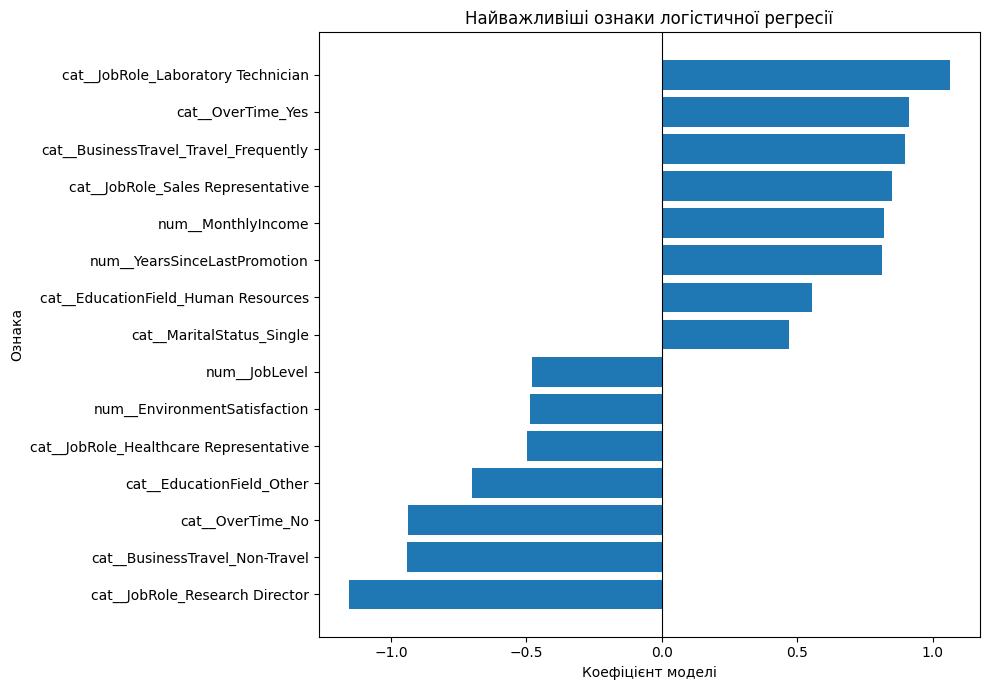

In [13]:
top_features = importance.head(15).sort_values('Coefficient')

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Coefficient']
)

plt.axvline(0, color='black', linewidth=0.8)
plt.title('Найважливіші ознаки логістичної регресії')
plt.xlabel('Коефіцієнт моделі')
plt.ylabel('Ознака')
plt.tight_layout()
plt.show()

Відбираємо 15% працівників із найвищим прогнозованим ризиком

In [14]:
# Відбираємо 15% працівників із найвищим прогнозованим ризиком
proba = candidates['Логістична регресія'].predict_proba(X_test)[:, 1]

top_n = int(np.ceil(len(y_test) * 0.15))
top_indices = np.argsort(proba)[-top_n:]

recall_top15 = y_test.iloc[top_indices].sum() / y_test.sum()

print(f"Recall@15%: {recall_top15:.3f}")

Recall@15%: 0.489


In [15]:
print("ROC-AUC:", round(results['Логістична регресія']['ROC-AUC'], 3))
print("Recall:", round(results['Логістична регресія']['Recall'], 3))
print("Recall@15%:", round(recall_top15, 3))

ROC-AUC: 0.816
Recall: 0.34
Recall@15%: 0.489


### 6. Висновок

6. Висновок
6.1. Результати моделювання
У результаті побудови логістичної регресії отримано такі показники:
0.816
ROC-AUC
Якість ранжування
0.340
Recall
Повнота прогнозу
0.489
Recall@15%
Охоплення у топ-15%

Інтерпретація результатів:
- ROC-AUC = 0.816. Модель має хорошу здатність розрізняти працівників із різним ризиком звільнення.
- Recall = 0.340. За стандартного порога класифікації модель виявляє 34% фактичних звільнень.
- Recall@15% = 0.489. Якщо HR зосередиться на 15% працівників із найвищим прогнозованим ризиком, можна охопити приблизно 48,9% усіх фактичних звільнень у тестовій вибірці.


6.2. Бізнес-інтерпретація
Результати показують, що модель може бути корисним інструментом для HR-відділу.

Особливо цікавий показник Recall@15%: замість аналізу всіх працівників компанія може зосередити увагу на невеликій групі з найвищим прогнозованим ризиком.

Це дозволяє:
- ефективніше розподіляти ресурси HR-відділу;
- своєчасно пропонувати працівникам підтримку;
- аналізувати фактори, пов'язані з плинністю персоналу;
- планувати заходи з утримання працівників.
6.3. Обмеження моделі
- Датасет містить лише 1470 записів.
- Частка працівників, які звільнилися, становить приблизно 16,1%.
- Recall на стандартному порозі 0.5 є відносно невисоким.
- Модель побудована на історичних даних, тому її результати можуть не відповідати майбутнім тенденціям.
- Виявлені залежності не означають, що певні характеристики безпосередньо спричиняють звільнення.
6.4. Подальше вдосконалення
Для покращення моделі можна:
1. Порівняти Logistic Regression із Random Forest та Gradient Boosting.
2. Оптимізувати поріг класифікації для збільшення Recall.
3. Використати Cross-Validation.
4. Дослідити важливість ознак за допомогою SHAP.
5. Перевірити економічну ефективність HR-програм утримання.


6.5. Фінальний висновок

У межах проєкту було побудовано модель машинного навчання Logistic Regression для прогнозування ризику звільнення працівників компанії на основі датасету IBM HR Analytics.

Після очищення даних, створення нових ознак та навчання моделі отримано ROC-AUC = 0.816, Recall = 0.340 та Recall@15% = 0.489.

Результати свідчать, що модель має хорошу здатність ранжувати працівників за ризиком звільнення. Зокрема, аналіз 15% працівників із найвищим прогнозованим ризиком дозволяє охопити 48,9% фактичних звільнень у тестовій вибірці.

Отже, модель може бути корисною для HR-відділу як допоміжний інструмент для визначення пріоритетів у програмах підтримки та утримання персоналу.

Для подальшого покращення результатів доцільно порівняти логістичну регресію з іншими алгоритмами, оптимізувати поріг класифікації та провести додаткову перевірку стабільності моделі.

Важливо враховувати, що модель визначає статистичні закономірності, а не причини звільнення, тому її прогнози не повинні бути самостійною підставою для кадрових рішень.